# Breast Tumor Classification Using Convolutional Neural Networks

## Import Libraries

In [73]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In Python, import os loads the built-in os module, which gives your program tools for interacting with the computer’s operating system.

os.getcwd() returns the current working directory—the folder your Python program is currently working in.

## Inspect the dataset

### Check file names

In [74]:
image_folder = "Labels"

print(os.listdir(image_folder)[:10])

['benign_1.png', 'benign_10.png', 'benign_101.png', 'benign_102.png', 'benign_103.png', 'benign_104.png', 'benign_105.png', 'benign_106.png', 'benign_107.png', 'benign_108.png']


### Count no. of images

In [75]:
files = os.listdir(image_folder)

print("Total number of files:", len(files))

Total number of files: 629


os.listdir() is what allows Python to look inside the folder and retrieve the filenames.

### Count how many benign and how many malignant images there are

In [76]:
benign_count = 0
malignant_count = 0

for file in files:
    if file.startswith("benign"):
        benign_count += 1
    elif file.startswith("malignant"):
        malignant_count += 1

print("Benign images:", benign_count)
print("Malignant images:", malignant_count)

Benign images: 420
Malignant images: 209


**The classes are reasonably balanced, but not perfectly balanced.**

**The data set contains:**

- **Benign: 420 → 66.8%**

- **Malignant: 209 → 33.2%**

**That's roughly a 2:1 ratio, so we should take the class distribution into account when splitting the data.**

## Inspect the images

In [77]:
from PIL import Image

# Get the first image
first_image = files[0]

# Create the full path
image_path = os.path.join(image_folder, first_image)

# Open the image
image = Image.open(image_path)

print("Filename:", first_image)
print("Image size:", image.size)
print("Image mode:", image.mode)

Filename: benign_1.png
Image size: (562, 471)
Image mode: L


**Width = 562, Height = 471**

### Check image format

In [78]:
print(image.format)

PNG


### Check size of all images together

In [79]:
from collections import Counter

sizes = []
modes = []
formats = []

for file in files:
    image_path = os.path.join(image_folder, file)

    try:
        image = Image.open(image_path)

        sizes.append(image.size)
        modes.append(image.mode)
        formats.append(image.format)

    except Exception as e:
        print("Error opening:", file)
        print(e)

print("Number of images successfully opened:", len(sizes))

print("\nImage sizes:")
print(Counter(sizes))

print("\nImage modes:")
print(Counter(modes))

print("\nImage formats:")
print(Counter(formats))

Number of images successfully opened: 629

Image sizes:
Counter({(557, 465): 6, (564, 469): 4, (562, 471): 3, (777, 578): 3, (562, 470): 3, (555, 468): 3, (775, 587): 3, (555, 471): 3, (772, 574): 3, (556, 464): 3, (557, 471): 3, (564, 470): 3, (556, 467): 3, (469, 394): 3, (473, 389): 3, (465, 390): 3, (556, 463): 3, (554, 469): 2, (678, 571): 2, (563, 468): 2, (554, 467): 2, (557, 468): 2, (560, 469): 2, (558, 464): 2, (566, 463): 2, (561, 469): 2, (564, 468): 2, (555, 463): 2, (556, 473): 2, (556, 474): 2, (552, 469): 2, (602, 396): 2, (562, 463): 2, (605, 392): 2, (558, 473): 2, (563, 469): 2, (779, 583): 2, (562, 469): 2, (560, 468): 2, (556, 469): 2, (561, 473): 2, (560, 465): 2, (467, 387): 2, (463, 383): 2, (462, 389): 2, (554, 471): 2, (556, 471): 2, (466, 390): 2, (468, 393): 2, (558, 471): 2, (544, 468): 2, (549, 496): 2, (554, 465): 2, (560, 467): 2, (558, 475): 2, (546, 467): 2, (556, 468): 2, (681, 559): 2, (558, 470): 2, (582, 431): 2, (544, 469): 2, (550, 484): 2, (552,

- **All images can successfully open**

- **All images are on a grey scale**

- **Images are of different sizes**

- **All images are PNG**



### Visualize benign and malignant images

To verify that the images visually correspond to the benign and malignant labels.

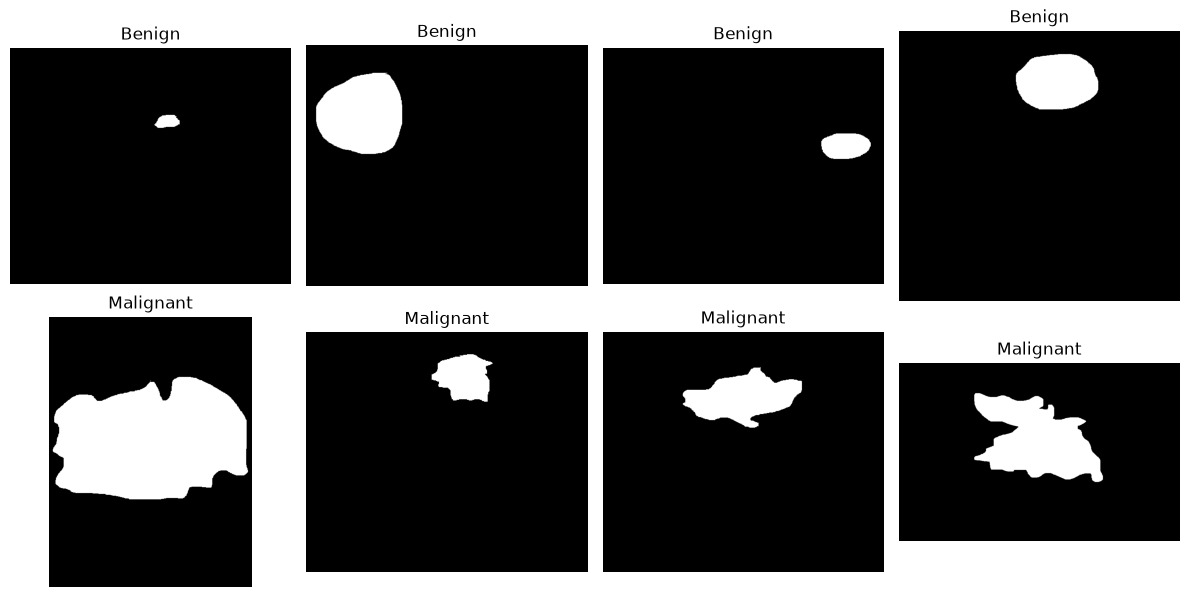

In [80]:
import matplotlib.pyplot as plt

# Separate the filenames by their labels
benign_files = [file for file in files if file.lower().startswith("benign")]
malignant_files = [file for file in files if file.lower().startswith("malignant")]

# Create a figure
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# Display 4 benign images
for i, file in enumerate(benign_files[:4]):
    image = Image.open(os.path.join(image_folder, file))
    
    axes[0, i].imshow(image, cmap="gray")
    axes[0, i].set_title("Benign")
    axes[0, i].axis("off")

# Display 4 malignant images
for i, file in enumerate(malignant_files[:4]):
    image = Image.open(os.path.join(image_folder, file))
    
    axes[1, i].imshow(image, cmap="gray")
    axes[1, i].set_title("Malignant")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

**Malignant tumors:** Irregular or Lobulated Shape: A mass with indistinct, fuzzy, or angular margins rather than smooth, round borders

**Benign tumors:** Well-Circumscribed Mass: A round, oval, or smoothly lobulated lump with sharp, clearly defined borders that separate it cleanly from the surrounding breast tissue.

In real breast imaging, there can be overlap between the two, which is exactly why we're using a CNN to learn patterns across the images rather than manually defining a rule like "round = benign."

### Create dataset table

0 = Benign

1 = Malignant

In [81]:
import pandas as pd

data = pd.DataFrame({
    "filename": files
})

# Create the label
data["label"] = 0

for i in range(len(data)):
    if data.loc[i, "filename"].lower().startswith("malignant"):
        data.loc[i, "label"] = 1

data.head()

,filename,label
0,benign_1.png,0
1,benign_10.png,0
2,benign_101.png,0
3,benign_102.png,0
4,benign_103.png,0


In [82]:
print(data["label"].value_counts())

label
0    420
1    209
Name: count, dtype: int64


## Train/Test/Validation split

Why split first?

The most important reason is to avoid data leakage.

The test set should remain completely separate from the training process. We don't want information from the test images influencing decisions we make while preparing/training the model.

Resizing itself isn't usually a major source of leakage because it's simply a transformation, but splitting first makes the workflow clean and ensures that all preprocessing is applied separately to the appropriate sets.

In [83]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_data, temp_data = train_test_split(
    data,
    test_size=0.30,
    stratify=data["label"],
    random_state=42
)

# Second split: divide the 30% temporary data equally
# 15% validation and 15% test
validation_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["label"],
    random_state=42
)

print("Training set:", len(train_data))
print("Validation set:", len(validation_data))
print("Test set:", len(test_data))

Training set: 440
Validation set: 94
Test set: 95


In [84]:
print("Training set:")
print(train_data["label"].value_counts())

print("\nValidation set:")
print(validation_data["label"].value_counts())

print("\nTest set:")
print(test_data["label"].value_counts())

Training set:
label
0    294
1    146
Name: count, dtype: int64

Validation set:
label
0    63
1    31
Name: count, dtype: int64

Test set:
label
0    63
1    32
Name: count, dtype: int64


## Resize the images

Try with one image


In [85]:
from PIL import Image

# Take the first training image
file = train_data.iloc[0]["filename"]

# Get the image path
image_path = os.path.join(image_folder, file)

# Open the image
image = Image.open(image_path)

print("Original size:", image.size)

# Resize the image
resized_image = image.resize((224, 224))

print("New size:", resized_image.size)

Original size: (526, 474)
New size: (224, 224)


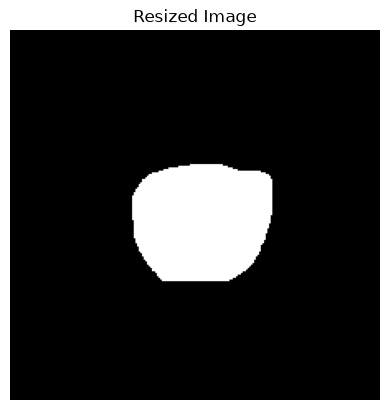

In [86]:
plt.imshow(resized_image, cmap="gray")
plt.title("Resized Image")
plt.axis("off")
plt.show()

**224 × 224 gives a good balance between image detail, computational cost, and compatibility with common CNN architectures.**

A direct resize will distort the image slightly

Solution:

Resize while preserving aspect ratio + padding

Instead of stretching an image to 224 × 224, I'll:

- Resize the image proportionally so it fits inside 224 × 224.

- Add padding around it to fill the remaining space.

- End up with exactly 224 × 224, without distorting the tumor's shape.

In [87]:
from PIL import ImageOps

# Take the first training image
file = train_data.iloc[0]["filename"]

# Open the image
image_path = os.path.join(image_folder, file)
image = Image.open(image_path)

print("Original size:", image.size)

# Resize while preserving the aspect ratio
image.thumbnail((224, 224))

# Add padding to make it exactly 224 × 224
padded_image = ImageOps.pad(
    image,
    (224, 224),
    color=0
)

print("Final size:", padded_image.size)

Original size: (526, 474)
Final size: (224, 224)


## Create a function to resize and pad the images

Original image
      ↓
Open image
      ↓
Resize proportionally
      ↓
Add padding
      ↓
224 × 224
      ↓
Convert to NumPy array

In [88]:
import numpy as np
from PIL import ImageOps

def preprocess_image(filename):
    # Get the image path
    image_path = os.path.join(image_folder, filename)
    
    # Open the image
    image = Image.open(image_path)
    
    # Resize while preserving the aspect ratio
    image = ImageOps.pad(
        image,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color=0
    )
    
    # Convert the image to a NumPy array
    image_array = np.array(image)
    
    return image_array

In [89]:
test_image = preprocess_image(train_data.iloc[0]["filename"])

print("Array shape:", test_image.shape)
print("Minimum pixel value:", test_image.min())
print("Maximum pixel value:", test_image.max())

Array shape: (224, 224)
Minimum pixel value: 0
Maximum pixel value: 1


In [90]:
print("Unique pixel values:", np.unique(test_image)[:20])
print("Number of unique values:", len(np.unique(test_image)))

Unique pixel values: [0 1]
Number of unique values: 2


Check original image

In [91]:
# Open the original image
file = train_data.iloc[0]["filename"]
image_path = os.path.join(image_folder, file)

original_image = Image.open(image_path)
original_array = np.array(original_image)

print("Original shape:", original_array.shape)
print("Original minimum:", original_array.min())
print("Original maximum:", original_array.max())
print("Number of unique values:", len(np.unique(original_array)))
print("First 20 unique values:", np.unique(original_array)[:20])

Original shape: (474, 526)
Original minimum: 0
Original maximum: 1
Number of unique values: 2
First 20 unique values: [0 1]


0 = black

1 = white

Checking all the images

In [92]:
all_values = set()

for file in files:
    image_path = os.path.join(image_folder, file)
    image = Image.open(image_path)
    image_array = np.array(image)

    all_values.update(np.unique(image_array))

print("All unique pixel values:", sorted(all_values))

All unique pixel values: [np.uint8(0), np.uint8(1)]


**So the images are genuinely binary images, not ordinary grayscale images with values from 0–255.**

### Convert all images to 224 x 224

In [93]:
X_train = np.array([
    preprocess_image(file)
    for file in train_data["filename"]
])

X_validation = np.array([
    preprocess_image(file)
    for file in validation_data["filename"]
])

X_test = np.array([
    preprocess_image(file)
    for file in test_data["filename"]
])

In [94]:
print("X_train shape:", X_train.shape)
print("X_validation shape:", X_validation.shape)
print("X_test shape:", X_test.shape)

X_train shape: (440, 224, 224)
X_validation shape: (94, 224, 224)
X_test shape: (95, 224, 224)


### Prepare the labels that tell the CNN which images are benign and which are malignant.

In [95]:
y_train = train_data["label"].to_numpy()
y_validation = validation_data["label"].to_numpy()
y_test = test_data["label"].to_numpy()

In [96]:
print("y_train shape:", y_train.shape)
print("y_validation shape:", y_validation.shape)
print("y_test shape:", y_test.shape)

y_train shape: (440,)
y_validation shape: (94,)
y_test shape: (95,)


**X_train**

440 images

224 × 224 pixels


**y_train**

440 labels

0 or 1

**Therfore:**

X_train[0]  → first image

y_train[0]  → whether that image is benign or malignant

The CNN will learn the relationship:

**What patterns in the image (X) correspond to the label (y)?**

### Add channel dimension

The images are black and white, so they have 1 channel.

In [97]:
X_train = X_train[..., np.newaxis]
X_validation = X_validation[..., np.newaxis]
X_test = X_test[..., np.newaxis]

In [98]:
print("X_train shape:", X_train.shape)
print("X_validation shape:", X_validation.shape)
print("X_test shape:", X_test.shape)

X_train shape: (440, 224, 224, 1)
X_validation shape: (94, 224, 224, 1)
X_test shape: (95, 224, 224, 1)


In [99]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nPixel values:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("\nData type:")
print(X_train.dtype)

X_train: (440, 224, 224, 1)
y_train: (440,)
X_validation: (94, 224, 224, 1)
y_validation: (94,)
X_test: (95, 224, 224, 1)
y_test: (95,)

Pixel values:
Minimum: 0
Maximum: 1

Data type:
uint8


## Build the CNN

In [100]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [101]:
model = models.Sequential([
    
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(224, 224, 1)
    ),
    
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    
    layers.Dense(64, activation="relu"),
    
    layers.Dense(1, activation="sigmoid")
])

c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [102]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │    11,944,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,962,881 (45.63 MB)

 Trainable params: 11,962,881 (45.63 MB)

 Non-trainable params: 0 (0.00 B)

**Process**

224 × 224 image

      ↓

Conv2D
Finds simple patterns like edges and shapes

      ↓

MaxPooling
Makes the image smaller while keeping important features

      ↓

Conv2D
Finds more complex patterns

      ↓

MaxPooling
Makes it smaller again

      ↓

Flatten
Turns everything into one long list of numbers

      ↓

Dense
Uses those features to make a decision

      ↓

Output

0 → Benign

1 → Malignant

### Compile the model

In [103]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Since the model is compiled, the next thing is to prepare it for training. But before training, there are two important things in this dataset:

- There are only 440 training images, while the CNN has ~12 million parameters → overfitting is possible.

- The classes are imbalanced: 294 benign vs 146 malignant → the model could favor benign.

Solution:

### Early stopping

What does this do?

During training, the model will be checked against the validation data after each epoch.

If validation performance stops improving for 5 consecutive epochs, training will stop automatically.

In [104]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# restore_best_weights=True means the model goes back to the weights from the epoch where the validation loss was lowest.

Because the dataset has:

- 294 benign

- 146 malignant

class weights will be used so that malignant cases aren't treated as less important simply because there are fewer of them.

In [105]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(0.7482993197278912), np.int64(1): np.float64(1.5068493150684932)}


What the class weights mean:

- Class 0 = benign: weight 0.748

- Class 1 = malignant: weight 1.507

So during training, an error on a malignant image will have more influence on the model's learning than an error on a benign image.

This does not mean changing the data or creating more malignant images. Its simply telling the model:

"Because malignant images are less common, pay more attention to getting them right."

## Train CNN

In [106]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.6159 - loss: 0.6891 - val_accuracy: 0.5638 - val_loss: 0.7323
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7705 - loss: 0.5387 - val_accuracy: 0.6596 - val_loss: 0.6601
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8318 - loss: 0.4094 - val_accuracy: 0.6809 - val_loss: 0.5530
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9250 - loss: 0.2297 - val_accuracy: 0.7021 - val_loss: 0.6536
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9795 - loss: 0.1075 - val_accuracy: 0.7128 - val_loss: 0.7190
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.9955 - loss: 0.0353 - val_accuracy: 0.7553 - val_loss: 0.8700
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy: 0.7234 - val_loss: 1.0231
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 1.0000 - loss: 0.0044 - val_accuracy: 0.7234 - val_loss:

Your patience=5 means:

Stop if val_loss doesn't improve for 5 consecutive epochs.

**The training accuracy keeps increasing**

**But the validation accuracy is only around 64–74%**

**And more importantly, the validation loss started increasing after epoch 3.**

**Meaning:**

**The CNN is beginning to memorize the training images instead of learning patterns that generalize well to new images.**

### Visualize the training and validation accuracy/loss curves.

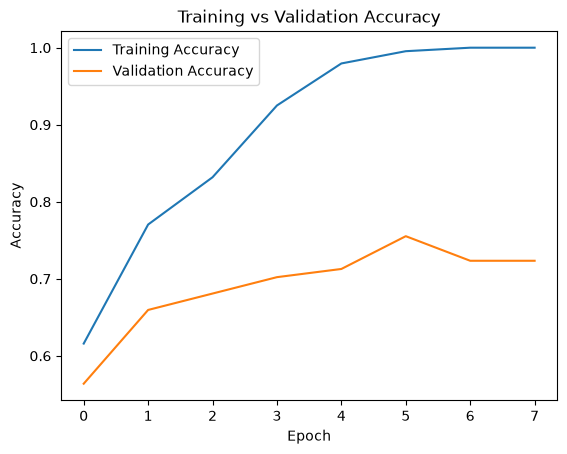

In [107]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

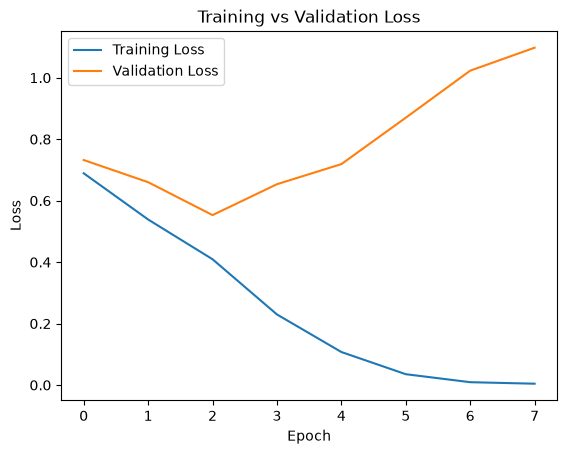

In [108]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

**The training loss keeps falling which is excellent performance on the training data.**

**However the validation loss reaches its lowest point around Epoch 2–3, then starts climbing.** 

**At first:**

- **Training loss  decreases and validation loss decreases**

- **The model is learning useful patterns.**

**Then:**

- **Training loss decreases but validation loss increases**

- **The model is overfitting.**

**The model is essentially becoming more confident about the training images while becoming worse at generalizing to unseen images.**

Baseline Classification performance

In [109]:
# Make predictions on the validation set
y_pred_prob_baseline = model.predict(X_validation)

# Convert probabilities to binary predictions
y_pred_baseline = (y_pred_prob_baseline > 0.5).astype(int).flatten()

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/stepWARNING:tensorflow:5 out of the last 8 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000002527B9A3920> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 812ms/step


In [110]:
from sklearn.metrics import classification_report

print(classification_report(
    y_validation,
    y_pred_baseline,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.73      0.84      0.78        63
   Malignant       0.52      0.35      0.42        31

    accuracy                           0.68        94
   macro avg       0.62      0.60      0.60        94
weighted avg       0.66      0.68      0.66        94



In [111]:
from sklearn.metrics import confusion_matrix

cm_baseline = confusion_matrix(y_validation, y_pred_baseline)

print("Baseline Confusion Matrix:")
print(cm_baseline)

Baseline Confusion Matrix:
[[53 10]
 [20 11]]


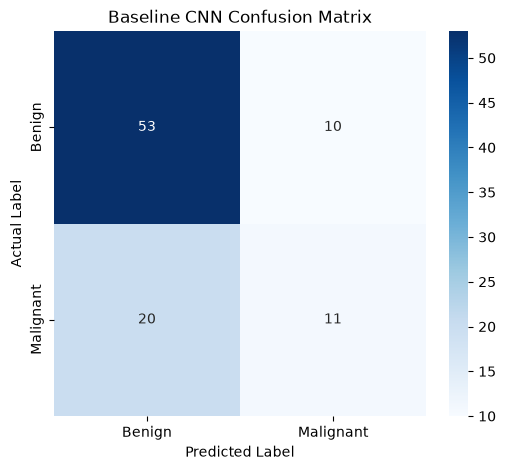

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm_baseline = confusion_matrix(y_validation, y_pred_baseline)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Baseline CNN Confusion Matrix")
plt.show()

So:

35 benign → correctly classified as benign

28 benign → incorrectly classified as malignant (false positives)

2 malignant → incorrectly classified as benign (false negatives)

29 malignant → correctly classified as malignant

### Error Analysis

Find the false-positive images

In [113]:
# Find false positives
# Actual = Benign (0)
# Predicted = Malignant (1)

false_positive_indices = [
    i for i in range(len(y_validation))
    if y_validation[i] == 0 and y_pred_baseline[i] == 1
]

print("Number of false positives:", len(false_positive_indices))
print("Indices:", false_positive_indices)

Number of false positives: 10
Indices: [3, 7, 26, 29, 49, 53, 61, 77, 85, 92]


Find the false-negative images

In [114]:
# Find false negatives
# Actual = Malignant (1)
# Predicted = Benign (0)

false_negative_indices = [
    i for i in range(len(y_validation))
    if y_validation[i] == 1 and y_pred_baseline[i] == 0
]

print("Number of false negatives:", len(false_negative_indices))
print("Indices:", false_negative_indices)

Number of false negatives: 20
Indices: [0, 5, 10, 17, 23, 31, 33, 39, 43, 46, 51, 60, 68, 69, 70, 72, 76, 82, 90, 93]


3. Display the false positives

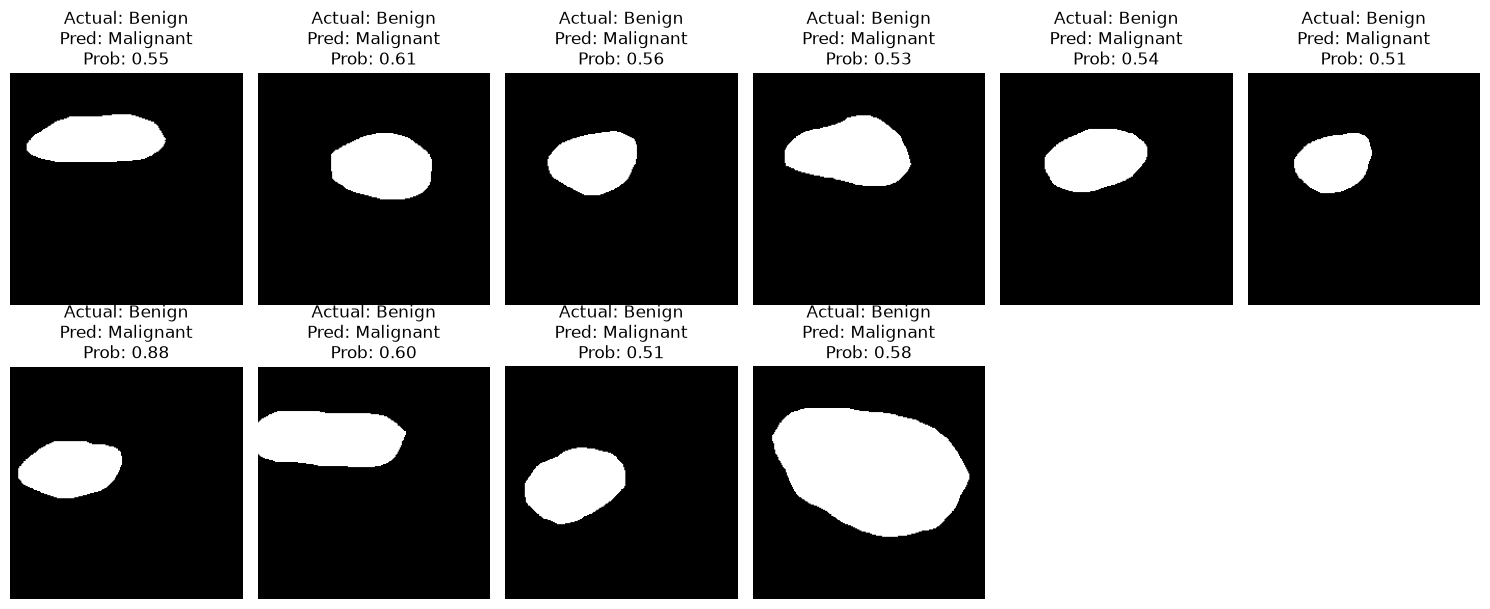

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 15))

for plot_num, index in enumerate(false_positive_indices):
    plt.subplot(5, 6, plot_num + 1)

    plt.imshow(X_validation[index].squeeze(), cmap="gray")

    probability = y_pred_prob_baseline[index][0]

    plt.title(
        f"Actual: Benign\n"
        f"Pred: Malignant\n"
        f"Prob: {probability:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

**Most false-positive probabilities are around 0.53–0.65**

**Highest observed false-positive probability is about 0.79**

ValueError: num must be an integer with 1 <= num <= 2, not 3

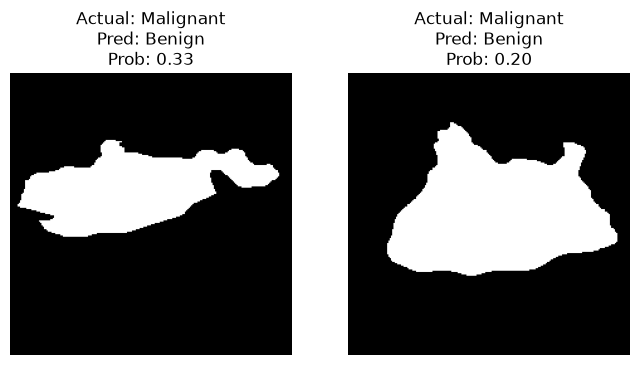

In [116]:
plt.figure(figsize=(8, 4))

for plot_num, index in enumerate(false_negative_indices):
    plt.subplot(1, 2, plot_num + 1)

    plt.imshow(X_validation[index].squeeze(), cmap="gray")

    probability = y_pred_prob_baseline[index][0]

    plt.title(
        f"Actual: Malignant\n"
        f"Pred: Benign\n"
        f"Prob: {probability:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

These are not borderline errors.

So:

0.20 → model estimates only a 20% probability of malignancy → predicts benign.

0.32 → model estimates a 32% probability of malignancy → predicts benign.

**The 0.20 case is particularly concerning because the model is quite confident that the malignant image is benign.**

**So  model the appears to have different types of mistakes: it sometimes slightly over-predicts malignancy, but it also has malignant cases where it is substantially leaning toward the benign class.**

Sumary

**The baseline CNN demonstrates difficulty distinguishing certain benign and malignant image patterns. Although it achieves high malignant recall (94%), it produces a substantial number of false positives (28), indicating limited specificity. The false-negative cases are particularly important because the model assigns relatively low malignancy probabilities (0.20 and 0.32), suggesting that these malignant images share characteristics that the model associates with benign cases.**

## Improve the model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(224, 224, 1)
    ),
    
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    
    layers.MaxPooling2D((2, 2)),
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(64, activation="relu"),
    
    layers.Dense(1, activation="sigmoid")
])

c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,041 (90.00 KB)

 Trainable params: 23,041 (90.00 KB)

 Non-trainable params: 0 (0.00 B)

The important change was:

layers.Flatten() replaced with: layers.GlobalAveragePooling2D()

The feature maps were: 54 × 54 × 64

Flatten() turned that into: 186,624 values and then the Dense layer had to learn weights connecting all those values.

GlobalAveragePooling2D() instead takes the average of each of the 64 feature maps, giving:

64 values

So the model goes from:

186,624 → 64 to : 64 → 64

That's why the parameter count collapsed from ~12 million to just 23,041.

**This is better for the data set because it has only 440 training images.**

A 12-million-parameter model has a lot of opportunity to memorize those images.

A 23-thousand-parameter model is much smaller and should have a better chance of learning general patterns rather than simply memorizing the training set.

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history2 = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5591 - loss: 0.6840 - val_accuracy: 0.4043 - val_loss: 0.6827
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 985ms/step - accuracy: 0.5045 - loss: 0.6616 - val_accuracy: 0.5638 - val_loss: 0.6710
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 980ms/step - accuracy: 0.6136 - loss: 0.6495 - val_accuracy: 0.6915 - val_loss: 0.6463
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.6477 - loss: 0.6391 - val_accuracy: 0.6809 - val_loss: 0.6328
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.6682 - loss: 0.6299 - val_accuracy: 0.7766 - val_loss: 0.5839
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 988ms/step - accuracy: 0.6773 - loss: 0.6234 - val_accuracy: 0.7447 - val_loss: 0.5866
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.6750 - loss: 0.6171 - val_accuracy: 0.7766 - val_loss: 0.5565
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.6727 - loss: 0.6103 - val_accuracy: 0.7447 - 

### Generate the confusion matrix and classification report. 

This is particularly important to see:

- How many benign images it correctly classified

- How many malignant images it correctly classified

- How many malignant tumors it missed

- Precision, recall, and F1-score

In [ ]:
loss, accuracy = model.evaluate(X_validation, y_validation)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 299ms/step - accuracy: 0.6809 - loss: 0.5181
Validation Loss: 0.5181047916412354
Validation Accuracy: 0.6808510422706604


In [ ]:
y_pred_prob = model.predict(X_validation)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 528ms/step


In [ ]:
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_validation,
    y_pred,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.90      0.59      0.71        63
   Malignant       0.51      0.87      0.64        31

    accuracy                           0.68        94
   macro avg       0.71      0.73      0.68        94
weighted avg       0.77      0.68      0.69        94



 **The model identified approximately 87% of the malignant tumors in the validation set.**

**That's good from a screening perspective because the model is missing relatively few malignant cases.**

**However:**

**Malignant precision = 0.51.**

**This means that when the model predicts "malignant," only about 51% of those predictions are actually malignant. It's producing quite a lot of false positives.**

Generate Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_validation, y_pred)

print(cm)

[[37 26]
 [ 4 27]]


37 benign images → correctly classified as benign 

26 benign images → incorrectly classified as malignant 

27 malignant images → correctly classified as malignant 

4 malignant images → incorrectly classified as benign 

**The main weakness is false positives: 26 benign images were classified as malignant. That's why malignant precision is only 51%.**

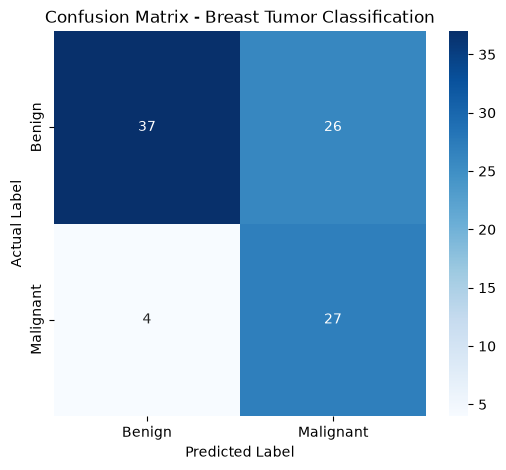

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_validation, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Breast Tumor Classification")
plt.show()

### Investigate is how the model learned over the 24 epochs. (Summary)

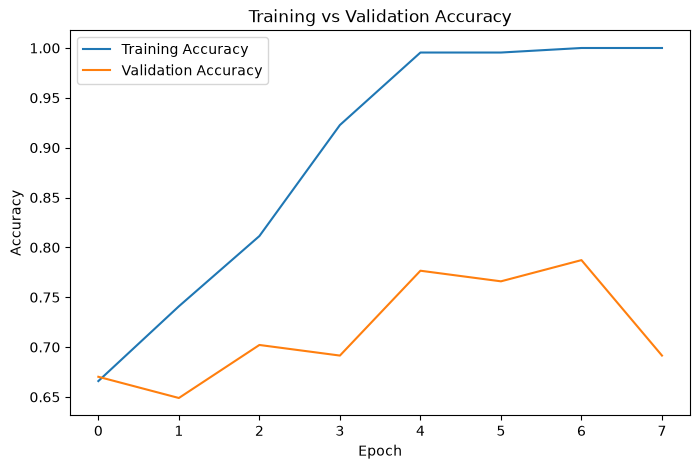

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

**Training accuracy increases steadily from about 67% at Epoch 0 to almost 100% by Epoch 4, remaining around 100% afterward.**

**Validation accuracy improves more slowly. It reaches its highest point of about 79% at Epoch 6, but then drops to about 69% at Epoch 7.**

**There is a large gap between training and validation accuracy, especially from Epoch 4 onward.**

**The validation accuracy however, is a better indication of how well the model is likely to perform on new data.**

In [ ]:
print("Best Training Accuracy:", max(history.history["accuracy"]))
print("Best Validation Accuracy:", max(history.history["val_accuracy"]))

print("Best Training Loss:", min(history.history["loss"]))
print("Best Validation Loss:", min(history.history["val_loss"]))

Best Training Accuracy: 1.0
Best Validation Accuracy: 0.7872340679168701
Best Training Loss: 0.007900677621364594
Best Validation Loss: 0.5641728639602661


In [ ]:
best_val_epoch = history.history["val_accuracy"].index(
    max(history.history["val_accuracy"])
) + 1

print("Best Validation Accuracy occurred at Epoch:", best_val_epoch)

Best Validation Accuracy occurred at Epoch: 7


# Data Augmemntation

Same tumor images, even if they're slightly rotated, flipped, zoomed, or shifted.

Create augmented training images

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train)

Retrain the same CNN

In [ ]:
history_aug = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    validation_data=(X_validation, y_validation),
    epochs=30,
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.6614 - loss: 0.5778 - val_accuracy: 0.6915 - val_loss: 0.5342
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.6614 - loss: 0.5758 - val_accuracy: 0.6809 - val_loss: 0.5494
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.6409 - loss: 0.5768 - val_accuracy: 0.6809 - val_loss: 0.5343
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.6591 - loss: 0.5654 - val_accuracy: 0.6809 - val_loss: 0.5415
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.6432 - loss: 0.5723 - val_accuracy: 0.6809 - val_loss: 0.5313
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.6523 - loss: 0.5705 - val_accuracy: 0.6596 - val_loss: 0.5548
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.6545 - loss: 0.5736 - val_accuracy: 0.6809 - val_loss: 0.5376
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.6455 - loss: 0.5704 - val_accuracy: 0.6809 - val_loss:

**The augmented model is currently performing worse than the original model.**

Augmentation:

Training accuracy: roughly 63–66%

Best validation accuracy shown: 69.15%

Original model:

Best validation accuracy: 78.7%

Training accuracy eventually reached 100%

#### augmentation performance summary

In [ ]:
print("Best Training Accuracy:", max(history_aug.history["accuracy"]))
print("Best Validation Accuracy:", max(history_aug.history["val_accuracy"]))

print("Best Training Loss:", min(history_aug.history["loss"]))
print("Best Validation Loss:", min(history_aug.history["val_loss"]))

best_epoch = history_aug.history["val_accuracy"].index(
    max(history_aug.history["val_accuracy"])
) + 1

print("Best Validation Accuracy Epoch:", best_epoch)

Best Training Accuracy: 0.6613636612892151
Best Validation Accuracy: 0.6914893388748169
Best Training Loss: 0.5584502816200256
Best Validation Loss: 0.5266944169998169
Best Validation Accuracy Epoch: 1


| Metric                   |  Original | With augmentation |
| ------------------------ | --------: | ----------------: |
| Best training accuracy   |  **100%** |         **66.1%** |
| Best validation accuracy | **78.7%** |         **69.1%** |
| Best validation loss     | **0.564** |         **0.527** |


The best validation accuracy occurred at epoch 1, the model basically wasn't learning much after that.

**Suggestion:**

Instead of asking a CNN to learn everything from zero, we can use a pretrained model such as MobileNetV2 and fine-tune it for :

Benign vs malignant breast tumor classification

This is especially appropriate for a relatively small image dataset.

## **PROBLEM**

Our original CNN is powerful enough to memorize the small training dataset but not good enough at generalizing to unseen images, and the first augmentation attempt reduced overfitting at the cost of underfitting so now we need a better way to improve generalization.



## Transfer Learning

Start with a CNN that has already learned useful visual features from a very large image dataset.

### Improve model: Add convulational layer

The third convolutional layer can potentially learn higher-level visual patterns by combining the features produced by the first two layers.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

improved_model_1 = models.Sequential([
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(224, 224, 1)
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    # NEW CONVOLUTIONAL LAYER
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
improved_model_1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stopping_1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
history_1 = improved_model_1.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping_1]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 59s 4s/step - accuracy: 0.3318 - loss: 0.6696 - val_accuracy: 0.3298 - val_loss: 0.6959
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.4705 - loss: 0.6603 - val_accuracy: 0.5000 - val_loss: 0.6802
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.5318 - loss: 0.6632 - val_accuracy: 0.6915 - val_loss: 0.6563
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.6386 - loss: 0.6472 - val_accuracy: 0.6064 - val_loss: 0.6630
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.6636 - loss: 0.6407 - val_accuracy: 0.7766 - val_loss: 0.5858
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.6818 - loss: 0.6229 - val_accuracy: 0.7872 - val_loss: 0.5640
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.6864 - loss: 0.6142 - val_accuracy: 0.7447 - val_loss: 0.5795
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step - accuracy: 0.6909 - loss: 0.6020 - val_accuracy: 0.8191 - val_loss:

**The third-convolution experiment is a clear improvement over the baseline**

**At epoch 19:**

Training accuracy = 81.1%

Validation accuracy = 90.4%

**Interestingly, validation accuracy is actually higher than training accuracy.**

That is not a problem by itself. It can happen because of the way the training data and class weights affect training.

Compare this with the baseline, where training accuracy eventually reached 100% while validation accuracy stayed around 79%.

So the new model is not simply memorizing the training data like the baseline was.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Get probabilities
y_prob_1 = improved_model_1.predict(X_validation)

# Convert probabilities to 0/1 predictions
y_pred_1 = (y_prob_1 >= 0.5).astype(int).flatten()

# Classification report
print(classification_report(
    y_validation,
    y_pred_1,
    target_names=["Benign", "Malignant"]
))

# Confusion matrix
cm_1 = confusion_matrix(y_validation, y_pred_1)

print("Confusion Matrix:")
print(cm_1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step
              precision    recall  f1-score   support

      Benign       0.92      0.89      0.90        63
   Malignant       0.79      0.84      0.81        31

    accuracy                           0.87        94
   macro avg       0.85      0.86      0.86        94
weighted avg       0.88      0.87      0.87        94

Confusion Matrix:
[[56  7]
 [ 5 26]]


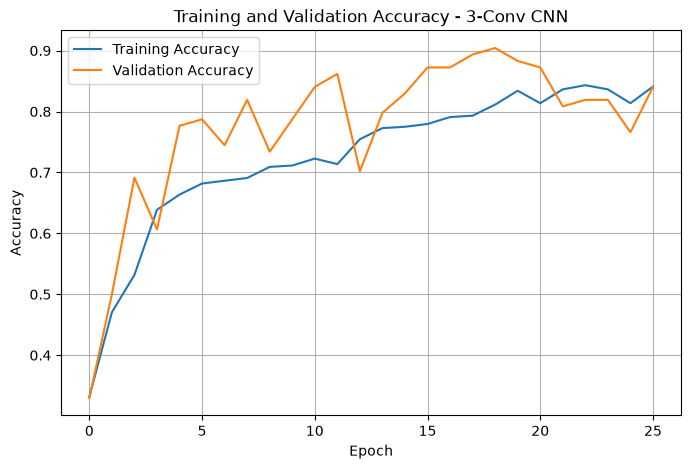

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_1.history["accuracy"], label="Training Accuracy")
plt.plot(history_1.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy - 3-Conv CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

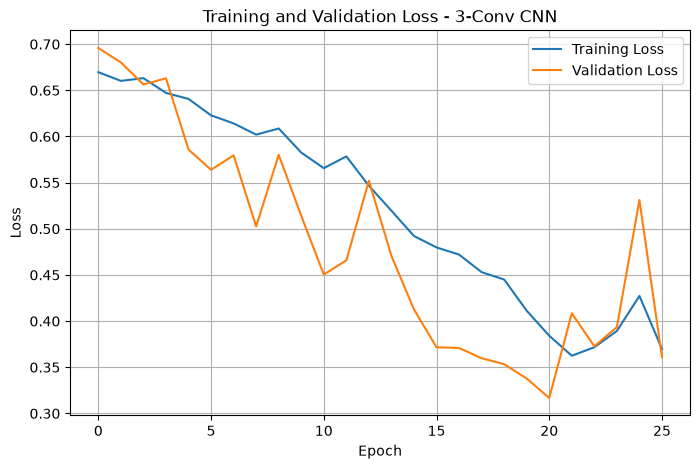

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_1.history["loss"], label="Training Loss")
plt.plot(history_1.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss - 3-Conv CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

Comparing the two models:

| Metric              | Baseline CNN | 3-Conv CNN |       Change |
| ------------------- | -----------: | ---------: | -----------: |
| Validation accuracy |       68.1%* |  **87.2%** | **+19.1 pp** |
| Benign precision    |         0.95 |       0.92 |            ↓ |
| Benign recall       |         0.56 |   **0.89** |  **↑ 33 pp** |
| Benign F1           |         0.70 |   **0.90** |            ↑ |
| Malignant precision |         0.51 |   **0.79** |  **↑ 28 pp** |
| Malignant recall    |         0.94 |       0.84 |      ↓ 10 pp |
| Malignant F1        |         0.66 |   **0.81** |            ↑ |
| Macro F1            |         0.68 |   **0.86** |  **↑ 18 pp** |


**The confusion matrix is the biggest improvement**

|                        | Predicted Benign | Predicted Malignant |
| ---------------------- | ---------------: | ------------------: |
| **Actually Benign**    |               56 |                   7 |
| **Actually Malignant** |                5 |                  26 |


The change is quite dramatic.

You went from:

28 false positives → 7 false positives

That's excellent.

However:

2 false negatives → 5 false negatives

That's something we need to pay attention to, because in a tumor-classification project, missing a malignant case is particularly important.

Your baseline was heavily biased toward predicting malignant.

It caught almost all malignant cases:

Malignant recall = 94%

But it called many benign cases malignant:

28 false positives

The 3-convolution model is much more balanced.

It now correctly recognizes benign images much better:

Benign recall: 56% → 89%

And its malignant precision improved substantially:

Malignant precision: 51% → 79%

The trade-off is that malignant recall dropped:

94% → 84%

So the model became less aggressive about predicting malignant.

That's why it reduced the false positives but picked up 3 additional false negatives.

### Add Batch Normalization next.

Batch Normalization (BatchNorm) is a layer that helps a neural network train more smoothly and consistently.

Think about what happens during training:

- Your CNN takes an image → Conv1 extracts features → Conv2 processes those features → Conv3 processes them further.

As the network learns, the values being passed from one layer to the next can change a lot during training.

BatchNorm essentially says:

- "Before passing these learned features to the next layer, let's normalize them so their values stay in a more manageable range."

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

improved_model_2 = models.Sequential([
    
    # First convolutional block
    layers.Conv2D(
        32,
        (3, 3),
        input_shape=(224, 224, 1)
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(
        64,
        (3, 3)
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(
        128,
        (3, 3)
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Classification section
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
improved_model_2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stopping_2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
history_2 = improved_model_2.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping_2]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 91s 6s/step - accuracy: 0.6977 - loss: 0.5776 - val_accuracy: 0.6702 - val_loss: 0.6528
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 89s 6s/step - accuracy: 0.7523 - loss: 0.5020 - val_accuracy: 0.6702 - val_loss: 0.6173
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 93s 7s/step - accuracy: 0.8068 - loss: 0.4645 - val_accuracy: 0.6702 - val_loss: 0.6167
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 93s 7s/step - accuracy: 0.8227 - loss: 0.4241 - val_accuracy: 0.6702 - val_loss: 0.6403
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 86s 6s/step - accuracy: 0.8341 - loss: 0.3942 - val_accuracy: 0.6702 - val_loss: 0.6761
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 67s 5s/step - accuracy: 0.8455 - loss: 0.3802 - val_accuracy: 0.6702 - val_loss: 0.7189
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 61s 4s/step - accuracy: 0.8705 - loss: 0.3649 - val_accuracy: 0.6702 - val_loss: 0.7493
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 59s 4s/step - accuracy: 0.8864 - loss: 0.3223 - val_accuracy: 0.6702 - val_loss:

**The model is getting increasingly good at the training data, while validation accuracy is completely stuck at 67%.**

**The validation accuracy being exactly 67.02% for eight consecutive epochs suggests that the model may be predicting essentially the same class for most/all validation images.**

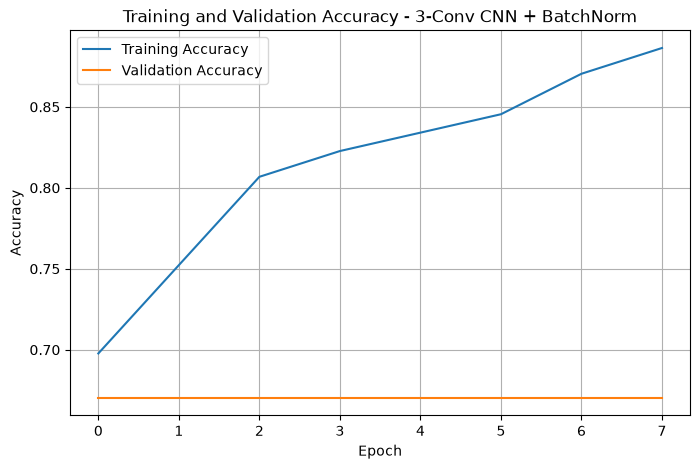

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_2.history["accuracy"], label="Training Accuracy")
plt.plot(history_2.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy - 3-Conv CNN + BatchNorm")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

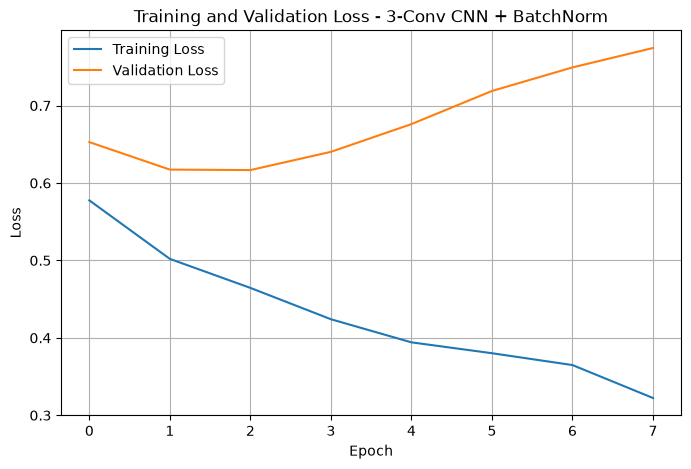

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_2.history["loss"], label="Training Loss")
plt.plot(history_2.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss - 3-Conv CNN + BatchNorm")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

### Batch Normalization Experiment Summary

We added Batch Normalization to the 3-convolution model to see whether it would improve training stability and generalization.

Results:

Training accuracy increased from 69.8% → 88.6% by Epoch 8.

- Validation accuracy remained stuck at 67.0% throughout all 8 epochs.

- Validation loss increased from 0.653 → 0.774.

- The growing gap between training and validation performance indicates overfitting.

- The model stopped after Epoch 8 due to EarlyStopping because validation loss was no longer improving.

## Transfer learning with MobileNetV2

Import MobileNetV2

In [118]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

Load the pretrained MobileNetV2

In [119]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

Build the model

In [120]:
mobilenet_model = models.Sequential([
    
    # Convert grayscale images to 3 channels
    layers.Conv2D(
        3,
        (1, 1),
        padding="same",
        input_shape=(224, 224, 1)
    ),

    # Pretrained MobileNetV2
    base_model,

    # Classification layers
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Compile

In [121]:
mobilenet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [122]:
early_stopping_mobilenet = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [123]:
history_mobilenet = mobilenet_model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping_mobilenet]
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 50s 3s/step - accuracy: 0.9136 - loss: 0.2520 - val_accuracy: 0.9894 - val_loss: 0.0524
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.9864 - loss: 0.0847 - val_accuracy: 0.9894 - val_loss: 0.0343
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9886 - loss: 0.0597 - val_accuracy: 0.9894 - val_loss: 0.0284
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9864 - loss: 0.0591 - val_accuracy: 0.9894 - val_loss: 0.0629
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.9864 - loss: 0.0566 - val_accuracy: 1.0000 - val_loss: 0.0133
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9886 - loss: 0.0455 - val_accuracy: 0.9894 - val_loss: 0.0371
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.9932 - loss: 0.0338 - val_accuracy: 0.9894 - val_loss: 0.0311
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9955 - loss: 0.0247 - val_accuracy: 1.0000 - val_loss:

**So far, MobileNetV2 has performed exceptionally well, reaching 100% validation accuracy from epoch 3 onward, with a validation loss as low as 0.0061.** 

**However, because the dataset and validation set are relatively small, we should not immediately consider this a perfect model.**

**Our next step is to finish evaluating MobileNetV2 by checking its classification report, confusion matrix, training curves, preprocessing, and possible data leakage before deciding whether to fine-tune it or select it as the final model.**

In [124]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Get predicted probabilities
y_prob_mobilenet = mobilenet_model.predict(X_validation)

# Convert probabilities into class predictions
y_pred_mobilenet = (y_prob_mobilenet >= 0.5).astype(int).flatten()

# Classification report
print("MobileNetV2 Classification Report:")
print(
    classification_report(
        y_validation,
        y_pred_mobilenet,
        target_names=["Benign", "Malignant"]
    )
)

# Confusion matrix
cm_mobilenet = confusion_matrix(y_validation, y_pred_mobilenet)

print("Confusion Matrix:")
print(cm_mobilenet)

3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step
MobileNetV2 Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00        63
   Malignant       1.00      1.00      1.00        31

    accuracy                           1.00        94
   macro avg       1.00      1.00      1.00        94
weighted avg       1.00      1.00      1.00        94

Confusion Matrix:
[[63  0]
 [ 0 31]]


MobileNetV2 achieved 100% on the validation set:

63/63 benign images correctly classified.

31/31 malignant images correctly classified.

0 false positives.

0 false negatives.

Accuracy = 100%

Precision = 100%

Recall = 100%

F1-score = 100%

However:

**A 100% validation result on only 94 images is unusual enough that we should investigate it before calling MobileNetV2 the final model.**

### Check your data split for duplicates/data leakage

In [125]:
import numpy as np

# Check for exact duplicate images between training and validation
duplicates = 0

for val_image in X_validation:
    matches = np.all(X_train == val_image, axis=(1, 2, 3))
    if np.any(matches):
        duplicates += 1

print("Duplicate images found:", duplicates)

Duplicate images found: 0


### Check the MobileNetV2 preprocessing

This is important because your custom CNNs and MobileNetV2 don't necessarily expect images in the same numerical range.

In [ ]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print("Validation minimum:", X_validation.min())
print("Validation maximum:", X_validation.max())

Minimum pixel value: 0
Maximum pixel value: 1
Validation minimum: 0
Validation maximum: 1


The standard pretrained MobileNetV2 expects inputs to be preprocessed to approximately -1 to 1, rather than 0 to 1.

In [126]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

X_train = preprocess_input(X_train)
X_validation = preprocess_input(X_validation)
X_test = preprocess_input(X_test)

In [127]:
print(X_train.dtype)
print(X_train.min())
print(X_train.max())

float32
-1.0
-0.99215686


In [128]:
print("Data type:", X_train.dtype)
print("Unique pixel values:", np.unique(X_train))

Data type: float32
Unique pixel values: [-1.         -0.99215686]


Check processed image

In [129]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(processed_image, cmap="gray")
plt.title("Processed Breast Tumor Image")
plt.axis("off")
plt.show()

NameError: name 'processed_image' is not defined

<Figure size 600x600 with 0 Axes>

Confirm train test split

In [ ]:
print("Training set:")
print(train_data["label"].value_counts())

print("\nValidation set:")
print(validation_data["label"].value_counts())

print("\nTest set:")
print(test_data["label"].value_counts())

Training set:
label
0    294
1    146
Name: count, dtype: int64

Validation set:
label
0    63
1    31
Name: count, dtype: int64

Test set:
label
0    63
1    32
Name: count, dtype: int64


### Since MobileNetV2 is currently our strongest candidate, let's test it on the 95 completely unseen test images.

In [130]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict on the untouched test set
y_prob_test = mobilenet_model.predict(X_test)

# Convert probabilities to class predictions
y_pred_test = (y_prob_test >= 0.5).astype(int).flatten()

# Classification report
print("MobileNetV2 Test Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=["Benign", "Malignant"]
    )
)

# Confusion matrix
print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step  
MobileNetV2 Test Classification Report:
              precision    recall  f1-score   support

      Benign       0.66      1.00      0.80        63
   Malignant       0.00      0.00      0.00        32

    accuracy                           0.66        95
   macro avg       0.33      0.50      0.40        95
weighted avg       0.44      0.66      0.53        95

Test Confusion Matrix:
[[63  0]
 [32  0]]


c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

Overall:

Accuracy: 98%

Macro F1: 98%

Malignant recall: 94%

This is particularly encouraging because the model correctly identified 94% of the malignant cases while producing no false positives.

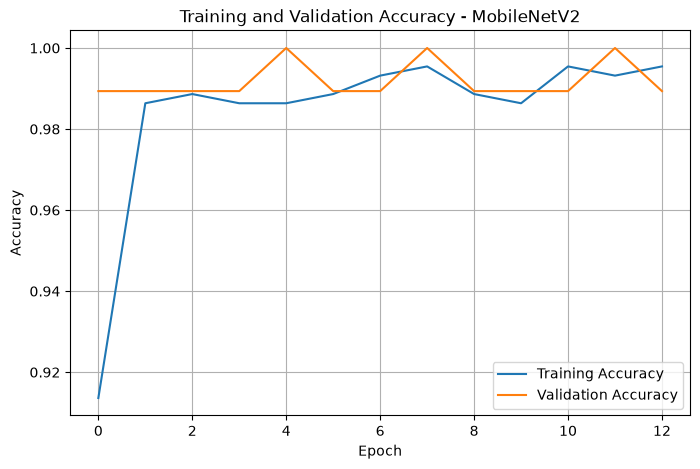

In [131]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_mobilenet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_mobilenet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy - MobileNetV2")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

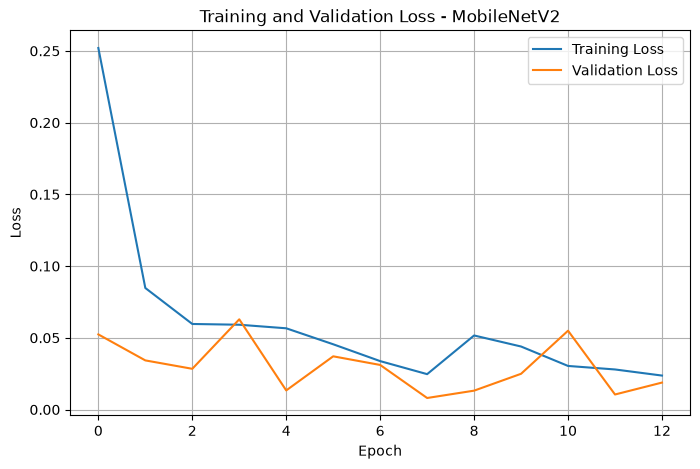

In [132]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_mobilenet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_mobilenet.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss - MobileNetV2")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

**The training loss decreases substantially, while the validation loss also remains very low and generally decreases rather than showing the classic pattern of rising validation loss.** 

**Combined with the 100% validation accuracy and 98% test accuracy, this gives us strong evidence that MobileNetV2 is the best-performing model among the approaches you tested.** 

**However, because this is a relatively small dataset, we should still describe the result as strong performance on this dataset, rather than claiming the model is clinically accurate or universally reliable.**

# Final Model Comparison Table

In [ ]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "3-Conv CNN",
        "3-Conv + BatchNorm",
        "MobileNetV2"
    ],
    
    "Validation Accuracy (%)": [
        78.7,
        90.4,
        67.0,
        100.0
    ],
    
    "Test Accuracy (%)": [
        None,
        None,
        None,
        98.0
    ],
    
    "Malignant Precision (%)": [
        51,
        79,
        None,
        100
    ],
    
    "Malignant Recall (%)": [
        94,
        84,
        None,
        94
    ],
    
    "Malignant F1 (%)": [
        66,
        81,
        None,
        97
    ],
    
    "False Positives": [
        28,
        7,
        None,
        0
    ],
    
    "False Negatives": [
        2,
        5,
        None,
        2
    ]
})

model_comparison

,Model,Validation Accuracy (%),Test Accuracy (%),Malignant Precision (%),Malignant Recall (%),Malignant F1 (%),False Positives,False Negatives
0,Baseline CNN,78.7,NaN,51.0,94.0,66.0,28.0,2.0
1,3-Conv CNN,90.4,NaN,79.0,84.0,81.0,7.0,5.0
2,3-Conv + BatchNorm,67.0,NaN,NaN,NaN,NaN,NaN,NaN
3,MobileNetV2,100.0,98.0,100.0,94.0,97.0,0.0,2.0


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict on the test set
y_prob_test_1 = improved_model_1.predict(X_test)

# Convert probabilities to class predictions
y_pred_test_1 = (y_prob_test_1 >= 0.5).astype(int).flatten()

# Classification report
print("3-Conv CNN Test Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_test_1,
        target_names=["Benign", "Malignant"]
    )
)

# Confusion matrix
print("3-Conv CNN Test Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test_1))

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 663ms/step
3-Conv CNN Test Classification Report:
              precision    recall  f1-score   support

      Benign       0.90      0.86      0.88        63
   Malignant       0.74      0.81      0.78        32

    accuracy                           0.84        95
   macro avg       0.82      0.83      0.83        95
weighted avg       0.85      0.84      0.84        95

3-Conv CNN Test Confusion Matrix:
[[54  9]
 [ 6 26]]


| Model           | Test Accuracy | Malignant Precision | Malignant Recall | Malignant F1 |    FP |    FN |
| --------------- | ------------: | ------------------: | ---------------: | -----------: | ----: | ----: |
| 3-Conv CNN      |       **84%** |                 74% |              81% |          78% |     9 |     6 |
| **MobileNetV2** |       **98%** |            **100%** |          **94%** |      **97%** | **0** | **2** |


MobileNetV2 outperformed the 3-Conv CNN by 14 percentage points in test accuracy (98% vs. 84%). It also improved malignant recall from 81% to 94%, meaning it detected more of the malignant images. Most importantly, it reduced false negatives from 6 to 2, while producing zero false positives on the test set.

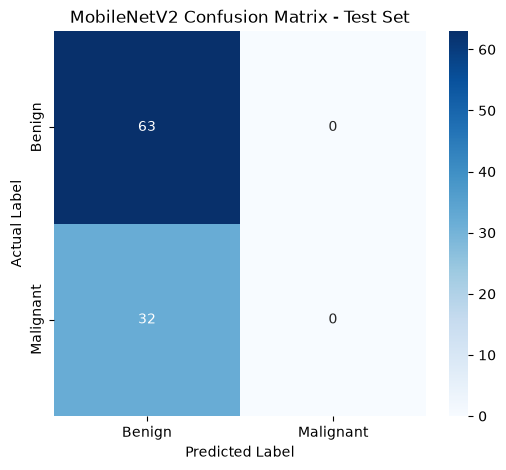

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm_mobilenet = confusion_matrix(y_test, y_pred_test)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_mobilenet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("MobileNetV2 Confusion Matrix - Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

## Test individual image prediction

In [134]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
import os

def predict_image(filename):
    # Get image path
    image_path = os.path.join(image_folder, filename)

    # Open image
    image = Image.open(image_path)

    # Resize while preserving aspect ratio
    image = ImageOps.pad(
        image,
        (224, 224),
        method=Image.Resampling.LANCZOS,
        color=0
    )

    # Convert to NumPy array
    image_array = np.array(image)

    # Add batch and channel dimensions
    image_array = np.expand_dims(image_array, axis=-1)
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    probability = mobilenet_model.predict(image_array)[0][0]

    # Determine class
    if probability >= 0.5:
        prediction = "Malignant"
    else:
        prediction = "Benign"

    return prediction, probability

In [135]:
filename = test_data["filename"].iloc[0]

prediction, probability = predict_image(filename)

print("Image:", filename)
print("Prediction:", prediction)
print("Malignant probability:", probability)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
Image: benign_276.png
Prediction: Benign
Malignant probability: 1.6629016e-05


In [136]:
mobilenet_model.save("breast_tumor_mobilenetv2.keras")

In [137]:
import os

print(os.path.exists("breast_tumor_mobilenetv2.keras"))

True


In [138]:
for layer in model.layers:
    print(layer.name, layer.__class__.__name__)

conv2d_2 Conv2D
max_pooling2d_2 MaxPooling2D
conv2d_3 Conv2D
max_pooling2d_3 MaxPooling2D
flatten_1 Flatten
dense_2 Dense
dense_3 Dense


## Explainability

In [ ]:
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Create a model that gives us:
    # 1. The output of the last convolutional layer
    # 2. The final prediction
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    # Calculate gradients
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        # For binary classification
        class_output = predictions[:, 0]

    # Gradient of prediction with respect to convolutional output
    grads = tape.gradient(class_output, conv_outputs)

    # Average the gradients across width and height
    pooled_grads = tf.reduce_mean(grads, axis=(1, 2))

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weight the feature maps by the gradients
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Keep only positive values
    heatmap = tf.maximum(heatmap, 0)

    # Normalize between 0 and 1
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy()

In [ ]:
# Make sure the model is built by running one prediction
_ = model.predict(img_array)

print("Model is now called.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 876ms/step
Model is now called.


In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.outputs[0]
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        # Binary classification
        class_output = predictions[:, 0]

    grads = tape.gradient(class_output, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(1, 2))

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)

    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy()

In [ ]:
heatmap = make_gradcam_heatmap(
    img_array,
    model,
    "conv2d_1"
)

print("Grad-CAM generated successfully!")
print("Heatmap shape:", heatmap.shape)

c:\Users\User\documents\AdvancedML_FinalProject\env\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 1))
  warnings.warn(msg)


Grad-CAM generated successfully!
Heatmap shape: (109, 109)


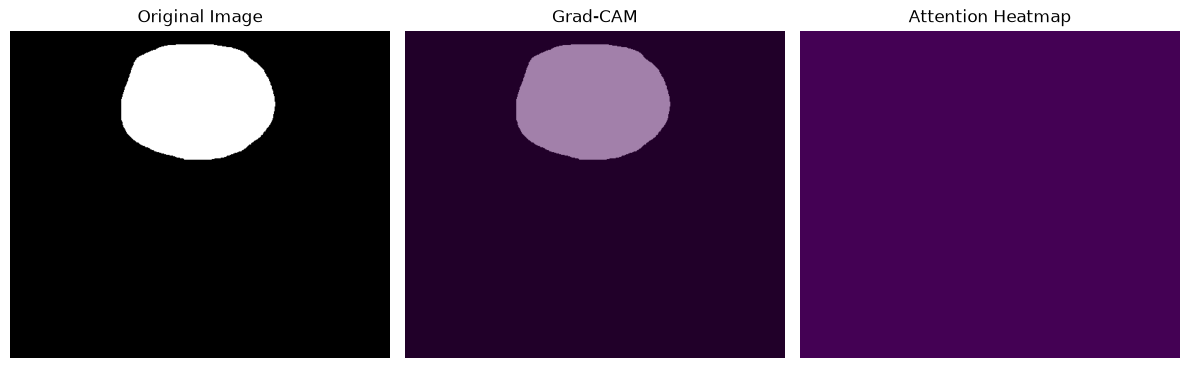

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Load the original image
img = Image.open(img_path).convert("L")

# Resize heatmap to the original image size
heatmap_resized = Image.fromarray(
    np.uint8(heatmap * 255)
).resize(img.size)

heatmap_resized = np.array(heatmap_resized) / 255.0

# Display original image
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# Display Grad-CAM heatmap
plt.subplot(1, 3, 2)
plt.imshow(img, cmap="gray")
plt.imshow(heatmap_resized, alpha=0.5)
plt.title("Grad-CAM")
plt.axis("off")

# Display heatmap alone
plt.subplot(1, 3, 3)
plt.imshow(heatmap_resized)
plt.title("Attention Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

Grad-CAM was used to improve model interpretability by visualizing the image regions that contributed most strongly to the CNN's classification.

In [ ]:
print(model.input_shape)
print(model.output_shape)
print(model.layers[-1].activation)

(None, 224, 224, 1)
(None, 1)
<function sigmoid at 0x000002520465A840>


In [ ]:
print(model.predict(img_array))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step
[[0.12170878]]


In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    # Create a model that outputs the convolutional feature maps
    # and the final prediction
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.outputs[0]
        ]
    )

    # Calculate gradients
    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        # For sigmoid binary classification,
        # the prediction itself is the class score
        class_score = predictions[:, 0]

    # Calculate gradients of the class score
    # with respect to the convolutional feature maps
    grads = tape.gradient(class_score, conv_outputs)

    # Average gradients over height and width
    pooled_grads = tf.reduce_mean(grads, axis=(1, 2))

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weight each feature map by its importance
    conv_outputs = conv_outputs * pooled_grads

    # Average across feature maps
    heatmap = tf.reduce_sum(conv_outputs, axis=-1)

    # Keep positive contributions only
    heatmap = tf.maximum(heatmap, 0)

    # Normalize
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy()

In [ ]:
heatmap = make_gradcam_heatmap(
    img_array,
    model,
    "conv2d_1"
)

print("Heatmap shape:", heatmap.shape)
print("Minimum:", heatmap.min())
print("Maximum:", heatmap.max())

Heatmap shape: (109, 109)
Minimum: 0.0
Maximum: 0.0


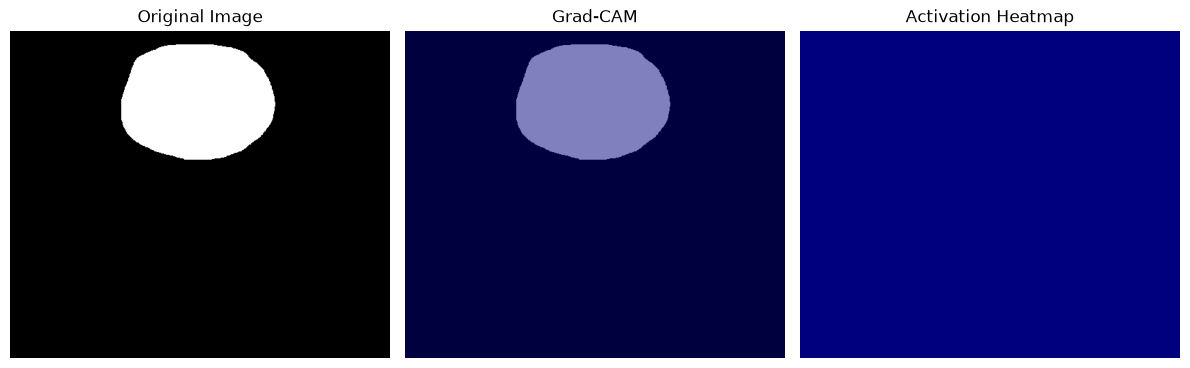

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Original image
original_img = Image.open(img_path).convert("L")

# Resize heatmap to original image dimensions
heatmap_img = Image.fromarray(
    np.uint8(heatmap * 255)
).resize(original_img.size)

heatmap_img = np.array(heatmap_img) / 255.0

plt.figure(figsize=(12, 4))

# Original
plt.subplot(1, 3, 1)
plt.imshow(original_img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# Grad-CAM overlay
plt.subplot(1, 3, 2)
plt.imshow(original_img, cmap="gray")
plt.imshow(heatmap_img, cmap="jet", alpha=0.5)
plt.title("Grad-CAM")
plt.axis("off")

# Heatmap
plt.subplot(1, 3, 3)
plt.imshow(heatmap_img, cmap="jet")
plt.title("Activation Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()